Chapter 5 found that predicting the direction of the whole market from its own history is close to hopeless. The question that quantitative equity funds actually answer is different: **which assets will do better than the others next month?** A long–short portfolio of the predicted winners against the predicted losers does not care whether the market rises or falls; it only needs the ranking to be slightly better than random.

This changes the statistics in our favour. Each month we make not one bet but dozens, one per asset. Grinold's **fundamental law of active management** says that a tiny skill multiplied over many independent bets adds up to a useful strategy. We derive it, then put it to work.

:::eli5
Guessing whether it will rain tomorrow is hard. Guessing which of 49 cities will be the sunniest tomorrow is also hard, but you get 49 guesses at once, and if you are right even slightly more often than chance on each one, the total score over a year can be impressive. That is the cross-sectional game.
:::

## Look at the big picture

**The problem.** Every month, rank the 49 US industry portfolios of Kenneth French's data library by their expected return next month, buy the top ten and sell the bottom ten (equal-weighted, dollar-neutral), and hold for a month. **The data:** monthly value-weighted returns since 1926, so that the walk-forward test covers more than half a century. **Measures:** the information coefficient (rank correlation between predictions and outcomes), the long–short Sharpe ratio after costs, and the **alpha** left after accounting for the standard Fama–French and momentum factors.

**Why industries rather than individual stocks?** Free stock data suffers from **survivorship bias**: the stocks you can download today are the ones that survived, so their history looks better than the market's real history was. Industry portfolios include every stock that existed at each date. The methods in this chapter apply unchanged to stocks, given point-in-time data (CRSP, Compustat and the like), which is how professionals use them.

## Get the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import stats
from sklearn.linear_model import Ridge
import lightgbm as lgb
import json, time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

ret = pd.read_csv(DATA / "industry49_monthly_vw.csv", index_col="month", parse_dates=True)
fac = pd.read_csv(DATA / "ff_factors_monthly.csv", index_col="month", parse_dates=True)
mkt = fac["mkt_rf"] + fac["rf"]
print(ret.shape, ret.index[0].date(), "→", ret.index[-1].date())
print("industries with data per decade:", ret.notna().sum(axis=1).groupby(ret.index.year // 10 * 10).mean().round(0).to_dict())

(1203, 49) 1926-07-31 → 2026-09-30
industries with data per decade: {1920: 41.0, 1930: 43.0, 1940: 43.0, 1950: 43.0, 1960: 46.0, 1970: 49.0, 1980: 49.0, 1990: 49.0, 2000: 49.0, 2010: 49.0, 2020: 49.0}


## The fundamental law of active management

:::math
Suppose each month we forecast the relative returns of $N$ assets and the correlation between our forecasts and the outcomes, the **information coefficient** (IC), is a small number $\rho$. Under simplifying assumptions (independent assets, forecasts scaled to their information content), the expected return per unit of active risk, the **information ratio**, is

$$\text{IR} \approx \text{IC} \times \sqrt{\text{BR}},$$

where the **breadth** BR is the number of independent bets per year. With 49 assets rebalanced monthly, $\text{BR} \leq 49 \times 12 = 588$, so an IC of just 0.03 could give an IR near $0.03\sqrt{588} \approx 0.7$. In practice industries are correlated, so the effective breadth is smaller, and the law is an upper bound. But it explains why a weak signal across many assets can beat a strong-looking signal on one.
:::

## Signals from scratch

All signals use only returns known at the end of month $t$ to predict month $t + 1$. Each has a published economic story.

| Signal | Definition (months) | Sign found for stocks | Source |
|---|---|---|---|
| `mom_12_1` | return over $t-11 \dots t-1$ (skip the last month) | + | Jegadeesh and Titman (1993); Moskowitz and Grinblatt (1999) for industries |
| `mom_6_1` | return over $t-5 \dots t-1$ | + | the same |
| `rev_1` | return in month $t$ | − | short-term reversal, Jegadeesh (1990) |
| `ltr_36_13` | return over $t-35 \dots t-12$ | − | long-term reversal, De Bondt and Thaler (1985) |
| `vol_12` | volatility of the last 12 monthly returns | − | low-risk anomaly, Ang et al. (2006) |
| `beta_36` | beta to the market over 36 months | − | betting against beta, Frazzini and Pedersen (2014) |
| `seas` | average return in the *same calendar month* over the past 10 years | + | seasonality, Heston and Sadka (2008) |
| `max_12` | largest monthly return in the last 12 months | − | lottery demand, Bali et al. (2011) |

In [2]:
def cumret(r, a, b):
    """compounded return from month t-a to t-b (inclusive), known at the end of month t"""
    g = np.log1p(r)
    return np.expm1(g.rolling(a - b + 1).sum().shift(b))

sig = {
    "mom_12_1": cumret(ret, 11, 1),
    "mom_6_1": cumret(ret, 5, 1),
    "rev_1": ret,
    "ltr_36_13": cumret(ret, 35, 12),
    "vol_12": ret.rolling(12).std(),
    "beta_36": ret.rolling(36).cov(mkt).div(mkt.rolling(36).var(), axis=0),
    "seas": sum(ret.shift(12 * k - 1) for k in range(1, 11)) / 10,      # same calendar month as t+1, years 1..10 ago
    "max_12": ret.rolling(12).max(),
}
SIGN = {"mom_12_1": 1, "mom_6_1": 1, "rev_1": -1, "ltr_36_13": -1, "vol_12": -1, "beta_36": -1, "seas": 1, "max_12": -1}
fwd = ret.shift(-1)                                                        # the target: next month's return

def cs_rank(df):
    """cross-sectional rank scaled to [-0.5, 0.5] each month (robust to outliers and scale)"""
    rk = df.rank(axis=1)
    return rk.sub(1).div(df.notna().sum(axis=1) - 1, axis=0) - 0.5

ranked = {k: cs_rank(v) * SIGN[k] for k, v in sig.items()}                 # oriented: higher = more attractive
print({k: int(v.notna().sum(axis=1).gt(20).sum()) for k, v in ranked.items()})

{'mom_12_1': 1192, 'mom_6_1': 1198, 'rev_1': 1203, 'ltr_36_13': 1168, 'vol_12': 1192, 'beta_36': 1168, 'seas': 1084, 'max_12': 1192}


`seas` uses `ret.shift(12k − 1)`: at the end of month $t$, the return of month $t + 1 - 12k$ is the return of the *same calendar month* as next month, $k$ years earlier, and it is already known. Writing that index correctly is the kind of detail that decides whether a backtest is honest.

The signs in the table come from studies of **individual stocks**. Whether they hold for industry portfolios is an empirical question, and we will see that several do not.

## Testing signals: the factor researcher's toolkit

### Information coefficients

In [3]:
def ic_series(score, target):
    """Spearman rank correlation, each month, over the assets that have both a score and an outcome."""
    ok = score.notna() & target.notna()
    out = {}
    for d in score.index:
        m = ok.loc[d]
        if m.sum() >= 20:
            out[d] = stats.spearmanr(score.loc[d, m], target.loc[d, m])[0]
    return pd.Series(out)

def nw_tstat(x, lags=6):
    x = np.asarray(x.dropna()); n = len(x); xc = x - x.mean()
    s = xc @ xc / n
    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * (xc[k:] @ xc[:-k]) / n
    return x.mean() / np.sqrt(s / n)

period = slice("1937", "2026")
ics = {k: ic_series(v.loc[period], fwd.loc[period]) for k, v in ranked.items()}
ic_tab = pd.DataFrame({k: {"mean IC": s.mean(), "IC t-stat (NW)": nw_tstat(s), "IC IR (annual)": s.mean() / s.std() * np.sqrt(12),
                           "share of months IC > 0": (s > 0).mean()} for k, s in ics.items()}).T.sort_values("mean IC", ascending=False)
print(ic_tab.round(3))
R["ic_mom"] = f"{ic_tab.loc['mom_12_1', 'mean IC']:.3f}"; R["t_mom"] = f"{ic_tab.loc['mom_12_1', 'IC t-stat (NW)']:.1f}"
R["best_sig"] = ic_tab.index[0]; R["best_ic"] = f"{ic_tab.iloc[0]['mean IC']:.3f}"
R["ic_rev"] = f"{ic_tab.loc['rev_1', 'mean IC']:+.3f}"; R["t_rev"] = f"{ic_tab.loc['rev_1', 'IC t-stat (NW)']:.1f}"
R["ic_seas"] = f"{ic_tab.loc['seas', 'mean IC']:.3f}"; R["t_seas"] = f"{ic_tab.loc['seas', 'IC t-stat (NW)']:.1f}"

           mean IC  IC t-stat (NW)  IC IR (annual)  share of months IC > 0
mom_12_1     0.063           7.589           0.790                   0.599
seas         0.044           7.229           0.749                   0.578
mom_6_1      0.039           4.834           0.516                   0.559
beta_36      0.009           0.839           0.103                   0.504
vol_12       0.008           0.832           0.098                   0.501
ltr_36_13   -0.003          -0.350          -0.042                   0.493
max_12      -0.012          -1.429          -0.161                   0.478
rev_1       -0.031          -3.687          -0.433                   0.443


ICs are small: the strongest signal, **mom_12_1** (industry momentum), has an average monthly rank correlation of 0.063 with next month's returns and a Newey–West t-statistic of 7.6 over 90 years; seasonality follows with 0.044 (t = 7.2). An IC of a few hundredths means the ranking is right only slightly more often than chance, which is normal and, by the fundamental law, can still be valuable.

The surprises are as instructive. `rev_1`, oriented for **reversal** as found in stocks, has an IC of -0.031 (t = -3.7): industries do not reverse last month's move, they *continue* it. Moskowitz and Grinblatt (1999) documented exactly this: individual stocks reverse at the one-month horizon (partly a microstructure effect of bid–ask bounce and liquidity), but industries show momentum even at one month. The low-risk signals (`vol_12`, `beta_36`) show nothing reliable across industries, and `max_12` has the wrong sign. **A signal documented for one kind of asset does not automatically transfer to another.**

### Quintile portfolios

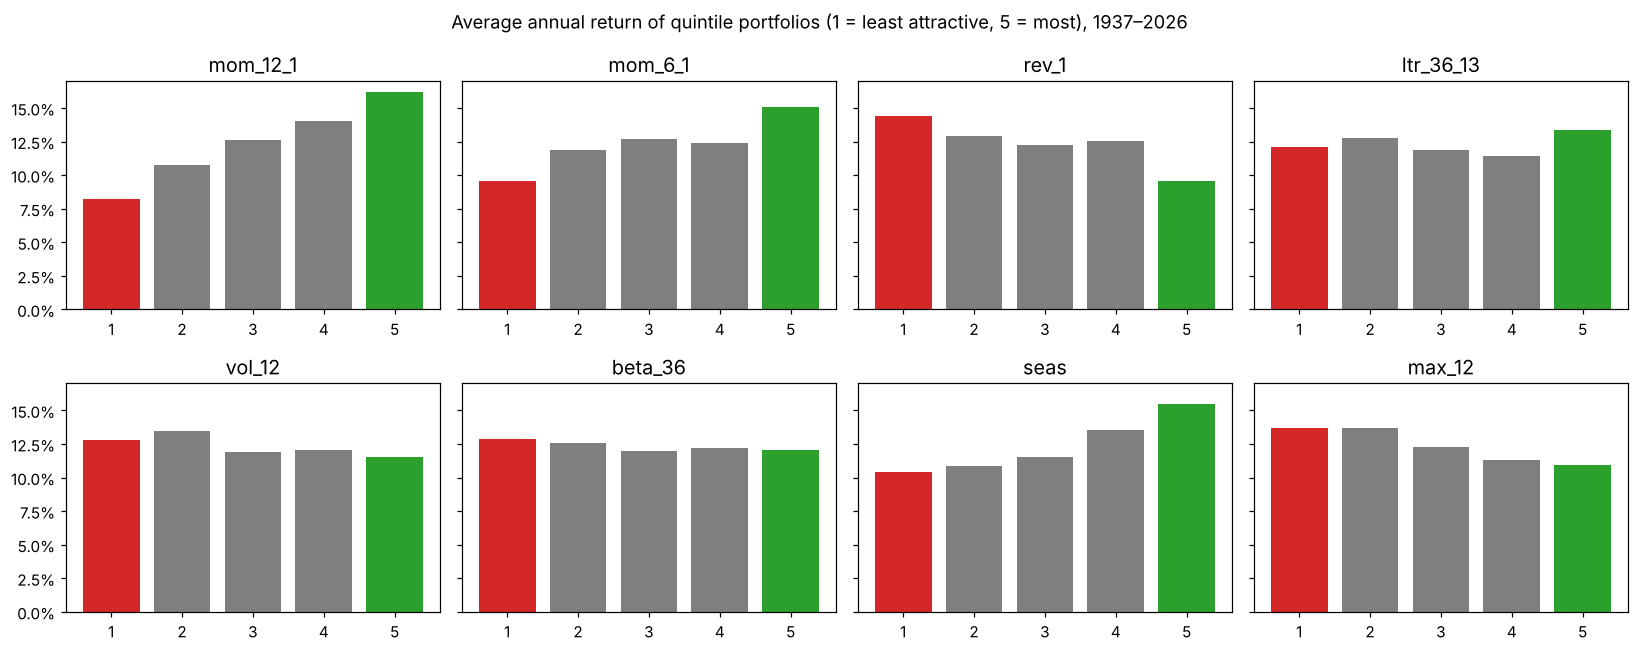

           Q5−Q1 annual  Sharpe  t (NW)
mom_12_1           0.08    0.55    5.28
seas               0.05    0.49    5.02
mom_6_1            0.05    0.39    3.95
ltr_36_13          0.01    0.10    0.88
beta_36           -0.01   -0.05   -0.43
vol_12            -0.01   -0.09   -0.79
max_12            -0.03   -0.23   -2.12
rev_1             -0.05   -0.39   -3.46


In [4]:
def quintile_returns(score, target, q=5):
    out = {}
    for d in score.index:
        s, t = score.loc[d], target.loc[d]; m = s.notna() & t.notna()
        if m.sum() < 20:
            continue
        g = pd.qcut(s[m].rank(method="first"), q, labels=False)
        out[d] = t[m].groupby(g).mean()
    return pd.DataFrame(out).T

qs = {k: quintile_returns(v.loc[period], fwd.loc[period]) for k, v in ranked.items()}
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, (k, q) in zip(axes.ravel(), qs.items()):
    m = q.mean() * 12
    ax.bar(range(1, 6), m, color=["tab:red", "tab:gray", "tab:gray", "tab:gray", "tab:green"])
    ax.set_title(k); ax.set_xticks(range(1, 6)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
fig.suptitle("Average annual return of quintile portfolios (1 = least attractive, 5 = most), 1937–2026")
save_fig("quintiles"); plt.show()
spreads = pd.DataFrame({k: q[4] - q[0] for k, q in qs.items()})
sp_tab = pd.DataFrame({"Q5−Q1 annual": spreads.mean() * 12, "Sharpe": spreads.mean() / spreads.std() * np.sqrt(12),
                       "t (NW)": spreads.apply(nw_tstat)}).sort_values("Sharpe", ascending=False)
print(sp_tab.round(2))

![Figure 6-1. Quintile sorts: for each signal, the average return of the fifth of industries it ranks least attractive (red) to most attractive (green). A good signal gives a staircase.](images/quintiles.png)

A useful signal produces a roughly **monotonic staircase**: each quintile better than the last. A signal whose spread comes from one extreme quintile only is more fragile (and often more expensive to trade).

### Fama–MacBeth regressions: which signals add something new?

Signals overlap: `mom_12_1` and `mom_6_1` are mostly the same information, and `vol_12`, `beta_36` and `max_12` all measure risk. Fama and MacBeth (1973) proposed a simple way to test them jointly.

:::math
Each month $t$, run a cross-sectional regression of next month's returns on all the (ranked) signals: $r_{i,t+1} = \gamma_{0,t} + \sum_k \gamma_{k,t}\, s_{k,i,t} + e_{i,t+1}$. This gives a time series of slopes $\gamma_{k,t}$. Their average is the premium of signal $k$ *holding the others fixed*, and its t-statistic uses the time-series variation of $\gamma_{k,t}$ (with a Newey–West correction), which automatically accounts for the correlation of assets within each month.
:::

In [5]:
def fama_macbeth(signals, target):
    keys = list(signals); rows = {}
    for d in target.index:
        Xd = pd.concat([signals[k].loc[d] for k in keys], axis=1, keys=keys)
        yd = target.loc[d]; m = Xd.notna().all(axis=1) & yd.notna()
        if m.sum() < 25:
            continue
        A = np.column_stack([np.ones(m.sum()), Xd[m].to_numpy()])
        rows[d] = np.linalg.lstsq(A, yd[m].to_numpy(), rcond=None)[0]
    G = pd.DataFrame(rows, index=["const"] + keys).T
    return pd.DataFrame({"premium (annual, per unit of rank)": G.mean() * 12, "t (NW)": G.apply(nw_tstat)}).drop("const")

fm = fama_macbeth({k: v.loc[period] for k, v in ranked.items()}, fwd.loc[period])
print(fm.round(3))
R["fm_sig"] = ", ".join(fm.index[fm["t (NW)"] > 2])

           premium (annual, per unit of rank)  t (NW)
mom_12_1                                0.106   5.109
mom_6_1                                -0.023  -1.241
rev_1                                  -0.026  -1.596
ltr_36_13                               0.018   1.248
vol_12                                 -0.007  -0.285
beta_36                                -0.018  -0.792
seas                                    0.068   6.432
max_12                                  0.013   0.672


Jointly, the signals with a Newey–West t-statistic above 2 are: **mom_12_1, seas**. These are the ones that carry information the others do not.

## From signals to a model: the walk-forward

Three ways to combine the eight signals into one score:

1. **Composite:** the average of the eight oriented ranks. No fitting at all; the directions come from the published literature, not from our data.
2. **Ridge regression** of next month's (ranked) return on the ranked signals: a linear model that learns the weights, with an $L_2$ penalty that shrinks them towards zero.
3. **LightGBM:** gradient-boosted trees on the same inputs, which can learn interactions (for example, momentum working differently for volatile industries).

Every January from 1970, the ridge and LightGBM models are refitted on the rows up to the previous November. Each row's label is the *next* month's return, so the November row's label is December's return, known by the time the first test row (end of January) is scored. Stopping at November rather than December adds one month of embargo as a safety margin. The refitted model then scores each month of the year.

In [6]:
keys = list(ranked)
panel = pd.concat({k: v.stack() for k, v in ranked.items()}, axis=1)
panel["target"] = cs_rank(fwd).stack()
panel["fwd"] = fwd.stack()
panel = panel.dropna(subset=keys + ["fwd"])
panel.index.names = ["month", "ind"]
print(panel.shape)

def walk_forward(model_fn, first=1970, last=2026):
    scores = []
    months = panel.index.get_level_values("month")
    for yr in range(first, last + 1):
        test = months.year == yr
        if not test.any():
            continue
        cutoff = pd.Timestamp(f"{yr - 1}-11-30")
        train = (months <= cutoff) & (months >= pd.Timestamp("1937-01-31"))
        mdl = model_fn()
        mdl.fit(panel.loc[train, keys].to_numpy(), panel.loc[train, "target"].to_numpy())
        scores.append(pd.Series(mdl.predict(panel.loc[test, keys].to_numpy()), index=panel.index[test]))
    return pd.concat(scores).unstack()

t0 = time.perf_counter()
pred = {
    "composite": panel[keys].mean(axis=1).unstack().loc["1970":],
    "ridge": walk_forward(lambda: Ridge(alpha=10.0)),
    "LightGBM": walk_forward(lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.02, num_leaves=8, min_child_samples=200,
                                                      subsample=0.7, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)),
}
print(f"walk-forward done in {time.perf_counter() - t0:.0f} s")

(50079, 10)


walk-forward done in 14 s


### Long–short portfolios, costs and alpha

In [7]:
def long_short(score, target, n=10, cost_bps=10):
    w_prev = pd.Series(dtype=float); out, tos = {}, {}
    for d in score.index:
        s = score.loc[d].dropna(); t = target.loc[d].reindex(s.index)
        s = s[t.notna()]
        if len(s) < 2 * n:
            continue
        w = pd.Series(0.0, index=s.index)
        w[s.nlargest(n).index] = 1 / n; w[s.nsmallest(n).index] = -1 / n
        to = w.sub(w_prev.reindex(w.index).fillna(0), fill_value=0).abs().sum() + w_prev.drop(w.index, errors="ignore").abs().sum()
        out[d] = (w * t.reindex(w.index)).sum() - to * cost_bps / 1e4
        tos[d] = to; w_prev = w
    return pd.Series(out), pd.Series(tos)

ls, tov = {}, {}
for k, sc in pred.items():
    ls[k], tov[k] = long_short(sc, fwd)
for k in ["mom_12_1", "rev_1", "vol_12", "seas"]:
    ls[k], tov[k] = long_short(ranked[k].loc["1970":], fwd)

def alpha_reg(x):
    F = fac[["mkt_rf", "smb", "hml", "mom"]].shift(-1).reindex(x.index)     # factor returns of the holding month
    A = np.column_stack([np.ones(len(x)), F.to_numpy()]); ok = np.isfinite(A).all(1) & np.isfinite(x.to_numpy())
    b, *_ = np.linalg.lstsq(A[ok], x.to_numpy()[ok], rcond=None)
    resid = x.to_numpy()[ok] - A[ok] @ b
    # Newey-West standard error of the intercept
    Xn = A[ok]; n = len(resid); XtX_inv = np.linalg.inv(Xn.T @ Xn)
    S = (Xn * resid[:, None]).T @ (Xn * resid[:, None]) / n
    for L in range(1, 7):
        G = (Xn[L:] * resid[L:, None]).T @ (Xn[:-L] * resid[:-L, None]) / n
        S += (1 - L / 7) * (G + G.T)
    V = n * XtX_inv @ S @ XtX_inv
    return b[0] * 12, b[0] / np.sqrt(V[0, 0]), b[4]

rows = {}
for k, x in ls.items():
    a, ta, bmom = alpha_reg(x)
    rows[k] = {"annual return": x.mean() * 12, "Sharpe": x.mean() / x.std() * np.sqrt(12), "turnover/month": tov[k].mean(),
               "alpha (annual)": a, "alpha t (NW)": ta, "momentum beta": bmom}
perf = pd.DataFrame(rows).T.sort_values("Sharpe", ascending=False)
print(perf.round(3))
R.update({f"sh_{k.replace(' ', '')}": f"{perf.loc[k, 'Sharpe']:.2f}" for k in ["composite", "ridge", "LightGBM", "mom_12_1"]})
R["a_comp"] = f"{perf.loc['composite', 'alpha (annual)']:.1%}"; R["ta_comp"] = f"{perf.loc['composite', 'alpha t (NW)']:.1f}"
R["a_lgb"] = f"{perf.loc['LightGBM', 'alpha (annual)']:.1%}"; R["ta_lgb"] = f"{perf.loc['LightGBM', 'alpha t (NW)']:.1f}"
R["mb_mom"] = f"{perf.loc['mom_12_1', 'momentum beta']:.2f}"

           annual return  Sharpe  turnover/month  alpha (annual)  \
ridge              0.056   0.419           2.022           0.016   
mom_12_1           0.067   0.415           0.871           0.003   
LightGBM           0.051   0.410           2.110           0.019   
seas              -0.001  -0.010           2.967           0.001   
composite         -0.007  -0.053           1.710          -0.014   
vol_12            -0.017  -0.115           0.562          -0.004   
rev_1             -0.105  -0.797           3.012          -0.102   

           alpha t (NW)  momentum beta  
ridge             1.487          0.650  
mom_12_1          0.206          0.893  
LightGBM          1.621          0.573  
seas              0.074         -0.004  
composite        -1.005          0.357  
vol_12           -0.207          0.195  
rev_1            -5.878         -0.181  


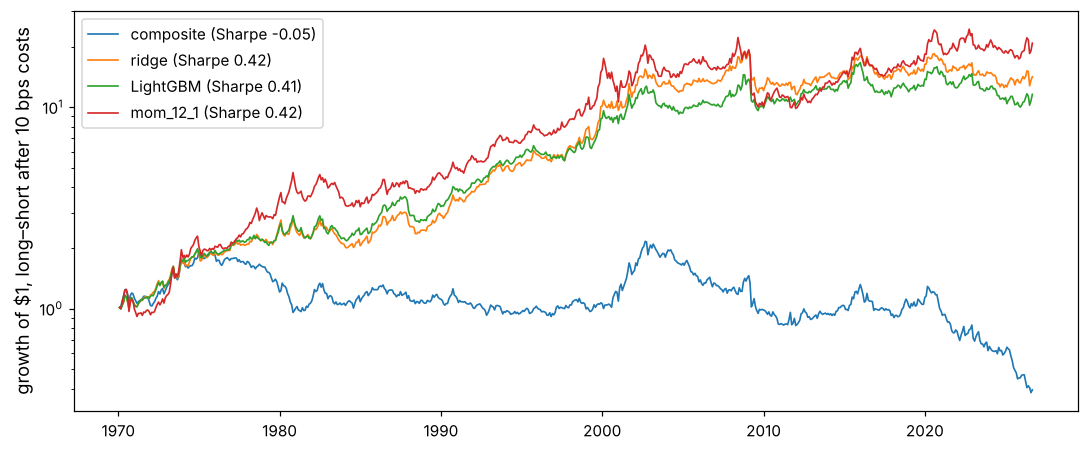

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for k in ["composite", "ridge", "LightGBM", "mom_12_1"]:
    ax.plot((1 + ls[k]).cumprod(), lw=1.1, label=f"{k} (Sharpe {perf.loc[k, 'Sharpe']:.2f})")
ax.set_yscale("log"); ax.legend(); ax.set_ylabel("growth of $1, long–short after 10 bps costs")
save_fig("long_short"); plt.show()

![Figure 6-2. Out-of-sample long–short portfolios (top 10 minus bottom 10 of 49 industries), 1970–2026, after costs.](images/long_short.png)

The composite, which copied its eight signs from the stock literature and fitted nothing, has a Sharpe ratio of -0.05: three of its ingredients point the wrong way for industries and cancel the good ones. Ridge (0.42) and LightGBM (0.41), which learn the weights *and signs* from past data in the walk-forward, recover a positive result, but no better than industry momentum on its own (0.42). After controlling for the market, size, value and momentum factors, LightGBM's alpha is 1.9% a year (t = 1.6), not significant. The momentum-only portfolio loads heavily on the stock-level momentum factor (beta 0.89): much of what looks like an industry signal is the well-known factor in disguise. **Alpha is what remains after you subtract what everyone already knows.**

## Momentum crashes and volatility scaling

Momentum has a dark side: rare, violent crashes, usually in sharp market rebounds after a bear market, when the losers of the past year (beaten-down, high-beta assets) jump the most.

worst months of industry momentum: {'2009-03': '-35.1%', '1970-08': '-16.9%', '2000-12': '-16.6%', '2026-06': '-14.4%', '2002-10': '-13.2%'}


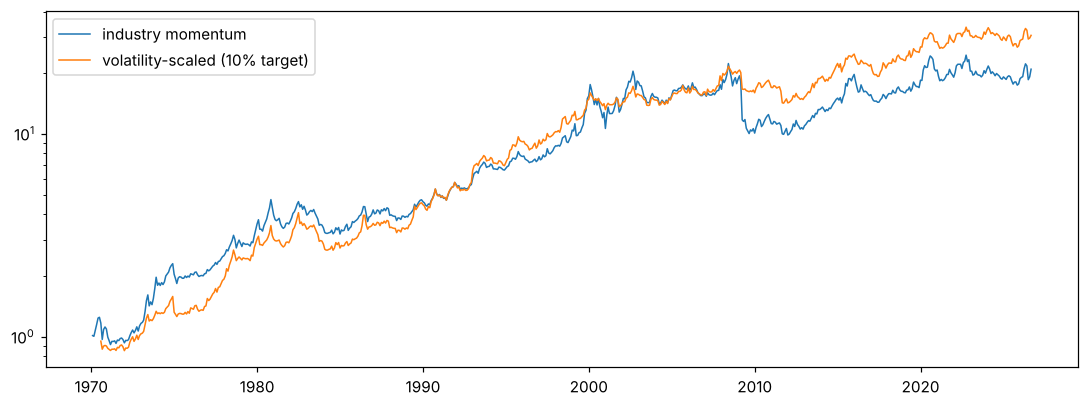

In [9]:
m_ls = ls["mom_12_1"]
worst = m_ls.nsmallest(5)
print("worst months of industry momentum:", {d.strftime("%Y-%m"): f"{v:.1%}" for d, v in worst.items()})
vol6 = m_ls.rolling(6).std().shift(1) * np.sqrt(12)
scaled = (0.10 / vol6).clip(upper=2) * m_ls                                # target 10% volatility, decided in advance
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot((1 + m_ls).cumprod(), lw=1, label="industry momentum")
ax.plot((1 + scaled.dropna()).cumprod(), lw=1, label="volatility-scaled (10% target)")
ax.set_yscale("log"); ax.legend(); save_fig("momentum_crash"); plt.show()
sm = lambda x: x.mean() / x.std() * np.sqrt(12)
R["sh_mom_raw"] = f"{sm(m_ls):.2f}"; R["sh_mom_vs"] = f"{sm(scaled.dropna()):.2f}"
R["worst_mom"] = f"{worst.iloc[0]:.0%}"; R["worst_mom_d"] = worst.index[0].strftime("%B %Y")
R["skew_raw"] = f"{stats.skew(m_ls):.2f}"; R["skew_vs"] = f"{stats.skew(scaled.dropna()):.2f}"

![Figure 6-3. Industry momentum and its volatility-scaled version. Scaling cuts exposure when the strategy has been volatile, which is when crashes cluster.](images/momentum_crash.png)

The worst month was March 2009 (-35%). Scaling the strategy to a constant 10% volatility using its own past six months of returns (an idea from Chapter 3, applied by Barroso and Santa-Clara, 2015) moves the Sharpe ratio from 0.42 to 0.54 and the skewness from -0.77 to -0.22.

## Does the edge decay?

In [10]:
dec = pd.DataFrame({k: ls[k].groupby(ls[k].index.year // 10 * 10).apply(sm) for k in ["composite", "ridge", "LightGBM", "mom_12_1"]})
print(dec.round(2))
pre, post = ics["mom_12_1"].loc[:"1993"], ics["mom_12_1"].loc["1994":]
print(f"industry momentum IC: {pre.mean():.3f} before 1994 vs {post.mean():.3f} after (publication of Jegadeesh–Titman, 1993)")
R["ic_pre"] = f"{pre.mean():.3f}"; R["ic_post"] = f"{post.mean():.3f}"
R["dec_last"] = f"{dec.loc[2020, 'composite']:.2f}" if 2020 in dec.index else "n/a"

      composite  ridge  LightGBM  mom_12_1
1970       0.21   0.85      0.91      0.86
1980      -0.02   0.15      0.25      0.26
1990      -0.01   1.12      1.04      1.03
2000       0.05   0.19      0.15     -0.06
2010       0.17   0.31      0.34      0.53
2020      -0.93  -0.10     -0.13      0.20
industry momentum IC: 0.077 before 1994 vs 0.039 after (publication of Jegadeesh–Titman, 1993)


Industry momentum's average IC was 0.077 before 1994 and 0.039 afterwards: it halved after the publication of the momentum literature. McLean and Pontiff (2016) found that published anomalies lose about a third to a half of their returns after publication, as investors trade on them. The decade table shows how uneven every model's performance is: no signal works in every decade, and a strategy chosen for its last decade will usually disappoint in the next.

## Present your solution

- **Finding.** In the cross-section of industries, the robust signals are **momentum** (12-month and, unlike stocks, 1-month) and **seasonality**. Signals that work for individual stocks (short-term reversal, low volatility, low beta, lottery stocks) do not transfer.
- **Models.** A composite with signs copied from the stock literature failed (Sharpe -0.05). Models that learned weights and signs from past data in a walk-forward (0.42 ridge, 0.41 LightGBM) worked, but did not beat volatility-scaled industry momentum (0.54), and their alphas after the four standard factors are not significant.
- **Why ML did not win here.** With ICs of a few hundredths and 49 correlated assets (about 23 independent ones, Exercise 3), there is little that a flexible model can learn beyond the signs. ML earns its keep with many more assets (thousands of stocks), more varied inputs (fundamentals, analyst data, text) and careful validation, which is where the large quantitative equity funds use it.
- **Risks.** Momentum crashes (use volatility scaling), decay after publication (the IC halved), crowding, and costs: industry portfolios are cheap to trade, individual small stocks are not.

## Try it out

::playground animations/factor_lab.html 640

Simulate the fundamental law with your own IC and breadth, and explore the real long–short returns of each signal and model, with and without volatility scaling, from any start year.

## Exercises

:::exercise
1. Replace the equal-weighted composite by an **IC-weighted** composite whose weights are each signal's average IC over the *previous* 20 years. Does it beat the equal-weighted one out of sample?
2. Use quintiles instead of top/bottom 10, and rank-weighted instead of equal-weighted positions. How do turnover and Sharpe change?
3. Estimate the **effective breadth** of the industry cross-section: the number of eigenvalues needed to explain 90% of the variance of the 49 industries' returns. Use it to compare the realised IR with the fundamental law.
4. Add a **sector-neutral** constraint: within each of five broad sectors you define, hold equal long and short weights. Does the composite's alpha change?
5. Run the LightGBM model with a **ranking objective** (`LGBMRanker`, with months as query groups). Compare with the regression version.
:::

<details><summary>Solutions</summary>

In [11]:
# 1 IC-weighted composite
ic_df = pd.DataFrame(ics)
w_ic = ic_df.rolling(240, min_periods=120).mean().shift(1).clip(lower=0)
comp_ic = sum(ranked[k].mul(w_ic[k], axis=0) for k in keys).loc["1970":]
x_ic, _ = long_short(comp_ic, fwd)
print("IC-weighted composite Sharpe:", round(sm(x_ic), 2), "| equal-weighted:", round(sm(ls["composite"]), 2))

# 3 effective breadth
C = ret.loc["1970":].dropna(axis=1).corr().to_numpy()
ev = np.sort(np.linalg.eigvalsh(C))[::-1]
k90 = int(np.searchsorted(np.cumsum(ev) / ev.sum(), 0.9) + 1)
print(f"{k90} components explain 90% of the variance; law with IC {ics['mom_12_1'].mean():.3f}: IR ≈ {ics['mom_12_1'].mean() * np.sqrt(k90 * 12):.2f}")

IC-weighted composite Sharpe: 0.37 | equal-weighted: -0.05
23 components explain 90% of the variance; law with IC 0.063: IR ≈ 1.05


</details>

## What's next

Cross-sectional strategies bet on broad patterns across many assets. Chapter 7 goes the other way: very specific relationships between pairs of related assets, the statistical arbitrage that made the reputation of the first quant funds, and the mathematics of mean reversion that governs it.

In [12]:
# data for the playground
Path("animations").mkdir(exist_ok=True)
pg = {k: [None if pd.isna(v) else round(float(v), 6) for v in ls[k].reindex(ls["composite"].index)] for k in ls}
payload = {"dates": [d.strftime("%Y-%m") for d in ls["composite"].index], "series": pg,
           "ic": {k: round(float(ics[k].mean()), 4) for k in ics}}
Path("animations/data.js").write_text("window.FACTOR_DATA = " + json.dumps(payload) + ";\n")
print(len(payload["dates"]), list(pg))

680 ['composite', 'ridge', 'LightGBM', 'mom_12_1', 'rev_1', 'vol_12', 'seas']
